**Célula 1 – setup e os três espaços:**

In [1]:
import os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd

from src.utils import set_seed, SEED, CLASS_NAMES, get_splits, plot_retrieval_panel
from src.representation import fit_pca, pca_project, load_autoencoder, ae_encode, compute_hog
from src.retrieval import SearchSpace, retrieve, precision_at_k

set_seed()
X_train, y_train, X_val, y_val, X_test, y_test = get_splits()
pca = fit_pca(X_train)

d = 32
ae = load_autoencoder(d, f"models/ae_{d}.pt")
spaces = [
    SearchSpace(f"shape (PCA-{d})", lambda X: pca_project(pca, X, d), X_train),
    SearchSpace("texture/edges (HOG)", compute_hog, X_train),
    SearchSpace(f"learned (AE-{d})", lambda X: ae_encode(ae, X), X_train),
]
os.makedirs("results/figures/retrieval_panels", exist_ok=True)

**Célula 2 – um painel por classe (as mesmas queries aleatórias da Etapa 8):**

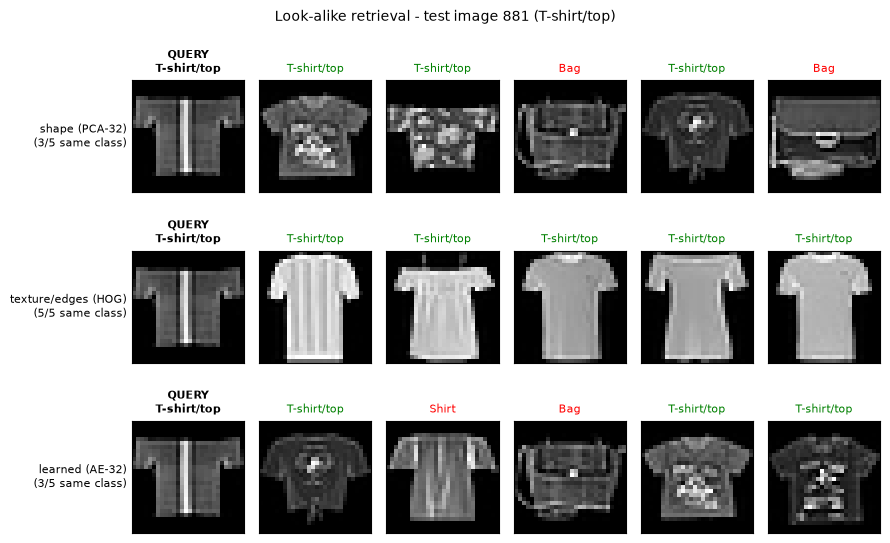

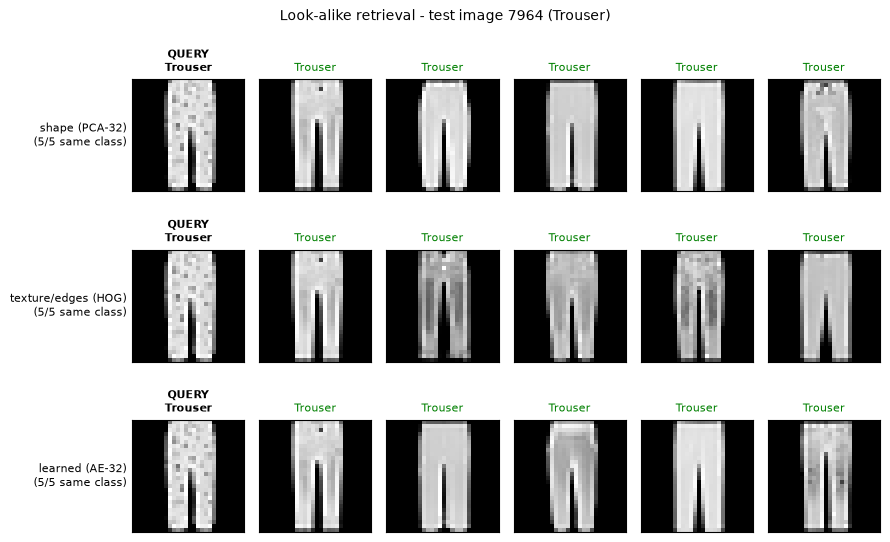

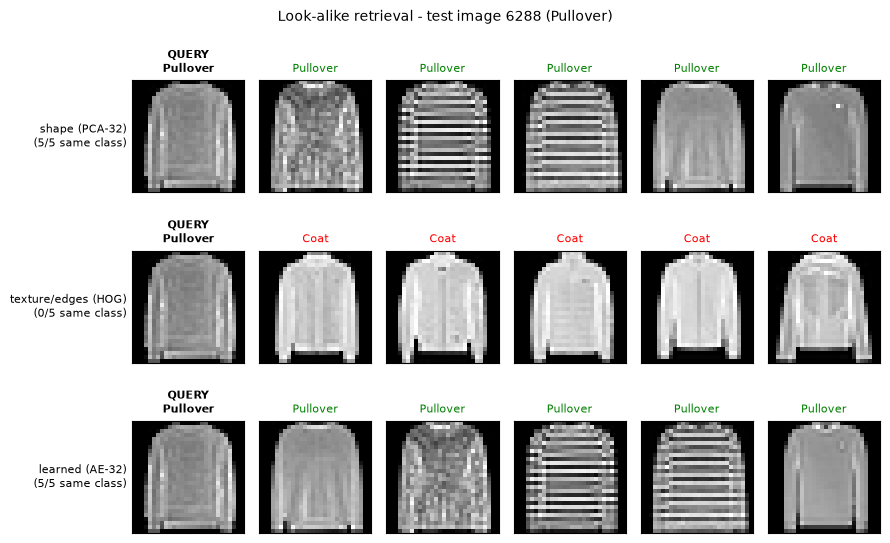

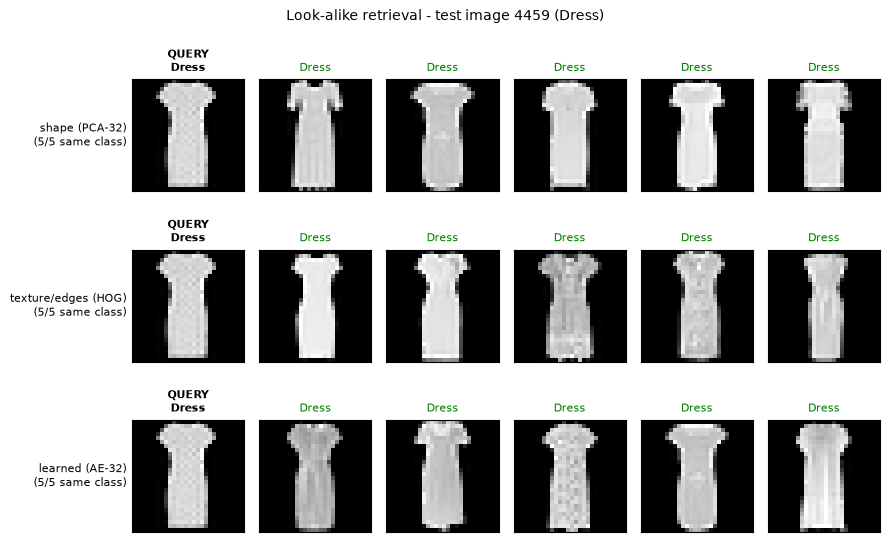

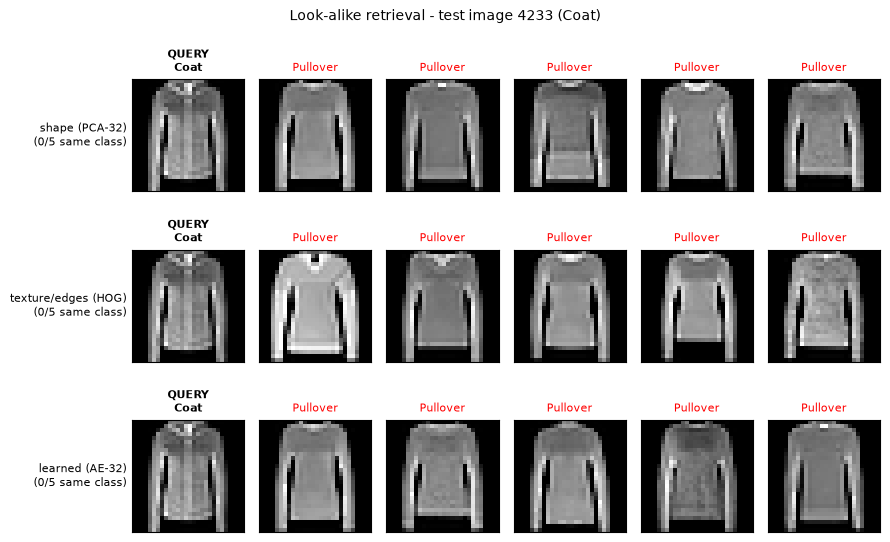

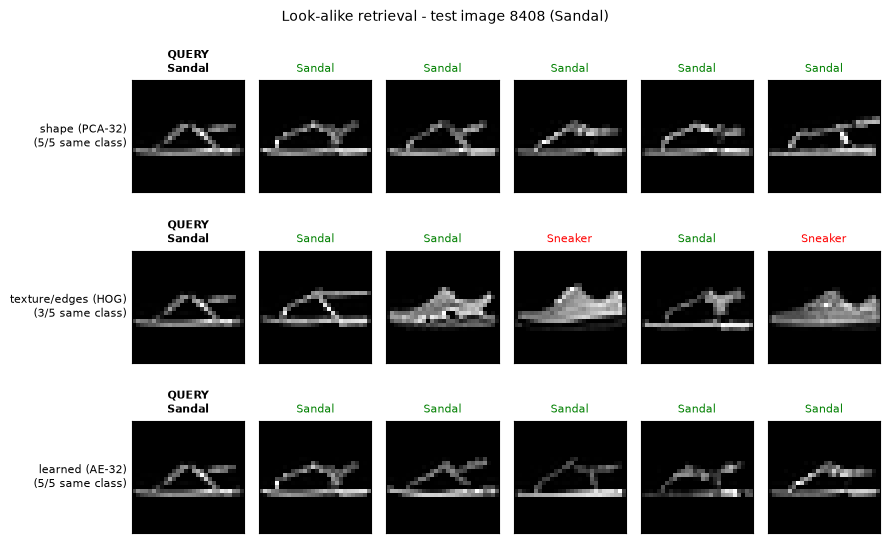

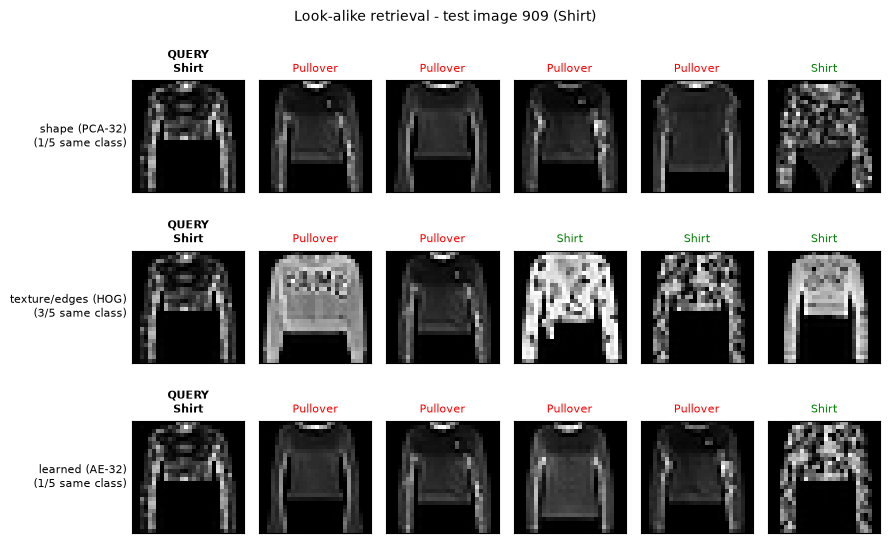

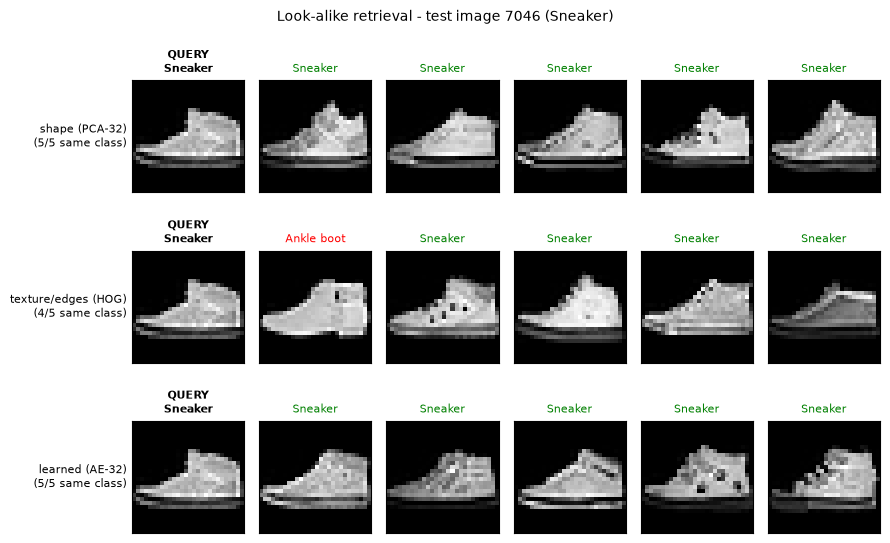

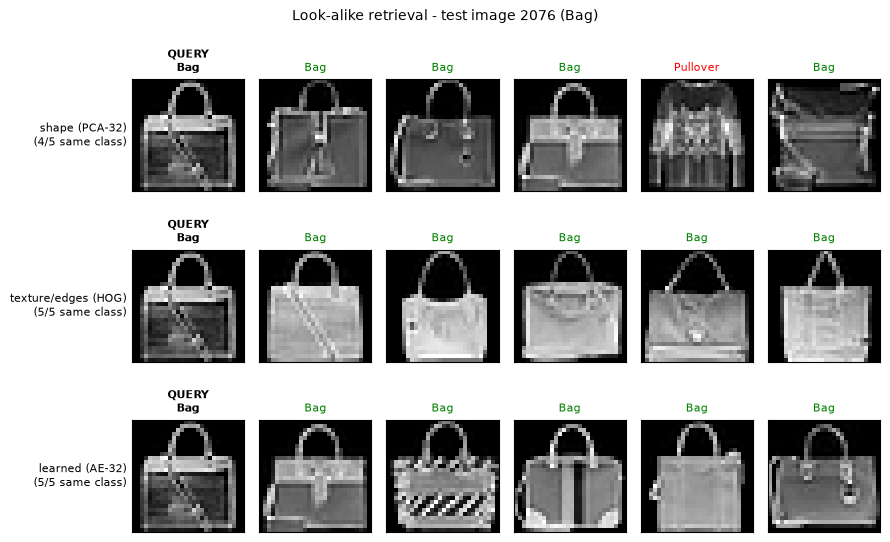

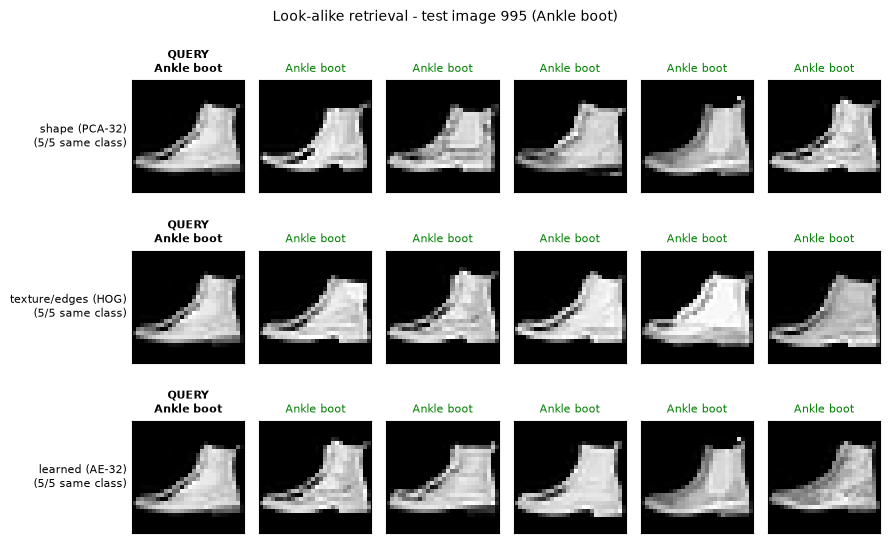

In [2]:
rng = np.random.default_rng(SEED)
example_idx = np.array([rng.choice(np.where(y_test == c)[0]) for c in range(10)])

for c, q in enumerate(example_idx):
    results = retrieve(X_test[q], spaces, k=5)                     
    name = CLASS_NAMES[c].replace("/", "-").replace(" ", "_")      
    plot_retrieval_panel(X_test[q], y_test[q], results, X_train, y_train, k=5,
                         title=f"Look-alike retrieval - test image {q} ({CLASS_NAMES[c]})",
                         save_path=f"results/figures/retrieval_panels/{c:02d}_{name}.png")

**Célula 3 – precision@10 por classe em cada espaço:**

In [3]:
per_class = {"class": CLASS_NAMES}
for space in spaces:
    idx, _ = space.search(X_test, k=10)                             
    per_class[space.name] = [
        precision_at_k(idx[y_test == c], y_train, y_test[y_test == c], 10)   
        for c in range(10)
    ]
per_class = pd.DataFrame(per_class)
print(per_class.round(3).to_string(index=False))
per_class.to_csv("results/tables/13_precision10_per_class.csv", index=False)

      class  shape (PCA-32)  texture/edges (HOG)  learned (AE-32)
T-shirt/top           0.738                0.737            0.762
    Trouser           0.951                0.944            0.956
   Pullover           0.660                0.625            0.698
      Dress           0.809                0.713            0.815
       Coat           0.669                0.663            0.688
     Sandal           0.839                0.818            0.875
      Shirt           0.543                0.537            0.570
    Sneaker           0.888                0.909            0.923
        Bag           0.944                0.934            0.949
 Ankle boot           0.925                0.940            0.943
